# 03 · Fock versus position representation (Sec. II C, Figs. 4–5)

The two quantics representations are related by the Hermite functions (Eqs. 11–13),
$\psi(x)=\sum_n\psi_n\phi_n(x)$. The paper builds this transform as a low-rank MPO with TCI; with dense arrays we can apply it exactly at the sizes below.

* **Fig. 4**: fidelity of Fock → position → Fock for a coherent state with $|\alpha|^2=2^{R_n}/3$, versus $(R_n,R_x)$.
* **Fig. 5**: QTT rank $\chi_q(t)$ of the driven Kerr oscillator in both bases.

**Box size.** The paper does not state $L$. We use $L = 2(\sqrt{2N+1}+6)$, which contains the classical turning points of every $\phi_{n<N}$ with margin; change `box()` to explore.

In [1]:
import os, sys
from tutorial_utils import *
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(backend_banner())
PAPER_SIZE = HAVE_QTTLIND and os.environ.get("QTTLIND_PAPER_SIZE") == "1"   # published sizes (hours); default: quick mode

qttlind 2.0.0, QTT solver: quick mode (set QTTLIND_PAPER_SIZE=1 for the published sizes).


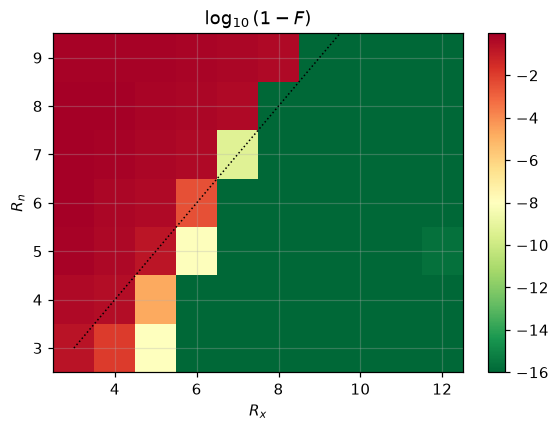

In [2]:
def box(N):
    return 2 * (np.sqrt(2 * N + 1) + 6)

def fock_to_x(psi_n, Rx):
    N = psi_n.size; L = box(N); dx = L / 2**Rx
    xg = -L/2 + dx * np.arange(2**Rx)
    Phi = hermite_functions(N, xg)            # (N, 2^Rx)
    return Phi, np.sqrt(dx) * (Phi.T @ psi_n)

def roundtrip_fidelity(Rn, Rx):
    N = 2**Rn
    psi = dr.coherent(N, np.sqrt(N / 3))
    Phi, psi_x = fock_to_x(psi, Rx)
    back = np.sqrt(box(N) / 2**Rx) * (Phi @ psi_x)
    return min(1.0, abs(np.vdot(psi, back)) / np.linalg.norm(back))   # fidelity with the normalised round-trip state

Rns = range(3, 10 if not PAPER_SIZE else 12)
Rxs = range(3, 13 if not PAPER_SIZE else 15)
F = np.array([[roundtrip_fidelity(Rn, Rx) for Rx in Rxs] for Rn in Rns])
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.pcolormesh(list(Rxs), list(Rns), np.log10(np.clip(1 - F, 1e-16, None)), cmap="RdYlGn_r", shading="nearest")
ax.plot(list(Rxs), list(Rxs), "k:", lw=1)
ax.set(xlabel=r"$R_x$", ylabel=r"$R_n$", ylim=(min(Rns) - .5, max(Rns) + .5), title=r"$\log_{10}(1-F)$")
plt.colorbar(im); savefig(fig, "fig04_fock_position_fidelity.png"); plt.show()

Reading: a coherent state stored on $R_n$ Fock bits needs at least as many bits in position space ($R_x \gtrsim R_n$, one more for small $R_n$) to survive the round trip — the green region sits on or right of the dotted diagonal. This is the paper's first argument for the Fock basis. The exact border depends on the box size $L$.

## Fig. 5 — rank of the evolving state in both bases

We evolve the driven Kerr oscillator of Eq. (32) exactly (dense 4th-order Magnus, step $10^{-2}$) and compress the state at each output time in both bases at relative error $10^{-8}$ (discarded weight $10^{-16}$). With `qttlind`, the evolution itself runs in QTT form with Magnus-TDVP and the ranks are read off the evolving state.

[dense Magnus-4 evolution] 4.90 s


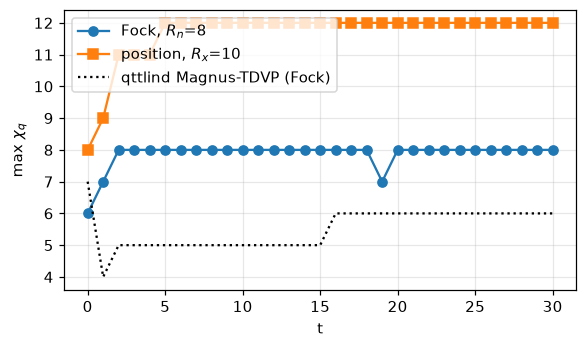

In [3]:
Rn = 10 if PAPER_SIZE else 8
Rx = Rn + 2
H0, H1 = driven_kerr(Rn)
N = 2**Rn
psi0 = dr.coherent(N, KERR["alpha0"])
t_out = np.linspace(0, 30, 31)
with timer("dense Magnus-4 evolution"):
    ts, states = magnus4_evolve(psi0, H0, H1, kerr_drive, t_out[-1], 1e-2, t_out)
Phi, _ = fock_to_x(psi0, Rx)
dx = box(N) / 2**Rx
chi_fock = [max(tt_ranks(tt_svd(s, Rn, 1e-16))) for s in states]
chi_x = [max(tt_ranks(tt_svd(np.sqrt(dx) * (Phi.T @ s), Rx, 1e-16))) for s in states]
if HAVE_QTTLIND:
    sysq = ql.System(); m = sysq.add_mode("osc", bits=Rn)
    H = KERR["omega0"] * m.n() + KERR["K"] / 2 * m.dag()**2 * m**2 + ql.coeff(kerr_drive) * (m**2 + m.dag()**2)
    rq = ql.evolve_closed(sysq.product_state(osc=ql.states.coherent(KERR["alpha0"])), H,
                          t_final=t_out[-1], dt=1e-2, method="magnus_tdvp", tol=1e-8, every=100)
fig, ax = plt.subplots(figsize=(6, 3.3))
ax.plot(ts, chi_fock, "o-", label=f"Fock, $R_n$={Rn}")
ax.plot(ts, chi_x, "s-", label=f"position, $R_x$={Rx}")
if HAVE_QTTLIND:
    ax.plot(rq.times, rq.track["chi_q"], "k:", label="qttlind Magnus-TDVP (Fock)")
ax.set(xlabel="t", ylabel=r"max $\chi_q$"); ax.legend()
savefig(fig, "fig05_rank_fock_vs_position.png"); plt.show()

As in the paper, $\chi_q$ barely changes in time — it measures correlations between scales of $n$ (or $x$), not entanglement — and the position representation needs a larger rank for the same state.